<h1 style="text-align: center;">Exploratory Data Analysis</h1>

## 1. Dowloading & Importing Libraries:

In [1]:
!pip install -q kagglehub

In [2]:
import pandas as pd
import numpy as np
import kagglehub
import os
import matplotlib.pyplot as plt
import seaborn as sns
import math

## 2. Loading Dataset:

In this file, I used **Google Colab** with a **Python 3** kernel to compile and run all cells.
- If you are running this on a local kernel, you can use the dataset file in the`data` folder (some minor code modifications may be required). 
- Alternatively, you can use Colab and run the cells below to use the dataset downloaded directly from Kaggle.

In [3]:
# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud


In [4]:
df = pd.read_csv(os.path.join(path, "creditcard.csv"))
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Exploratory Data Analysis (EDA):

### 3.1. Dataset Overview:

In [5]:
df.shape

(284807, 31)

In [6]:
# Dataset info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [7]:
# Basic statistics
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,...,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [8]:
# Check for missing values
missing = df.isnull().sum()
percent = (missing/len(df)) * 100
missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Percentage": percent
}).sort_values('Missing Count', ascending=False)

if missing_df['Missing Count'].sum() == 0:
    print("No missing values found!")
else:
    print(missing_df[missing_df['Missing Count'] > 0])

No missing values found!


In [9]:
# Check for duplicates
duplicates = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates}")

Number of duplicate rows: 1081


### 3.2. Target Variable Analysis:

**Let’s look at the distribution of the target class:**

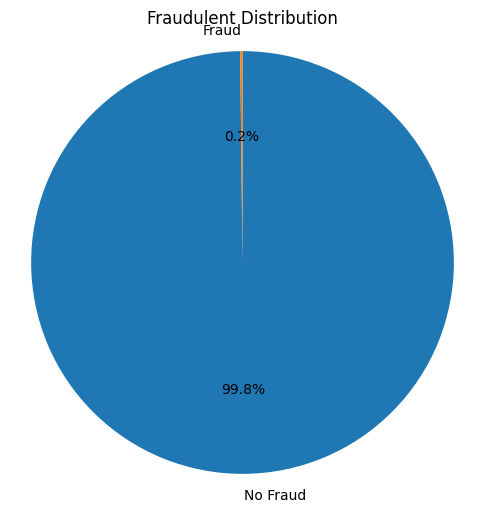

In [10]:
df_encoded = df.copy()
df_encoded['Class'] = df_encoded['Class'].map({0: 'No Fraud', 1: 'Fraud'})
counts = df_encoded['Class'].value_counts()

# Plot 
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, counterclock=False)
plt.title("Fraudulent Distribution")
plt.axis('equal')  
plt.show()

Through the above chart, significant class imbalance was detected.

### 3.3. Numerical Variable Analysis:

**Let's look at the distribution and potential outliers of the numerical features:**

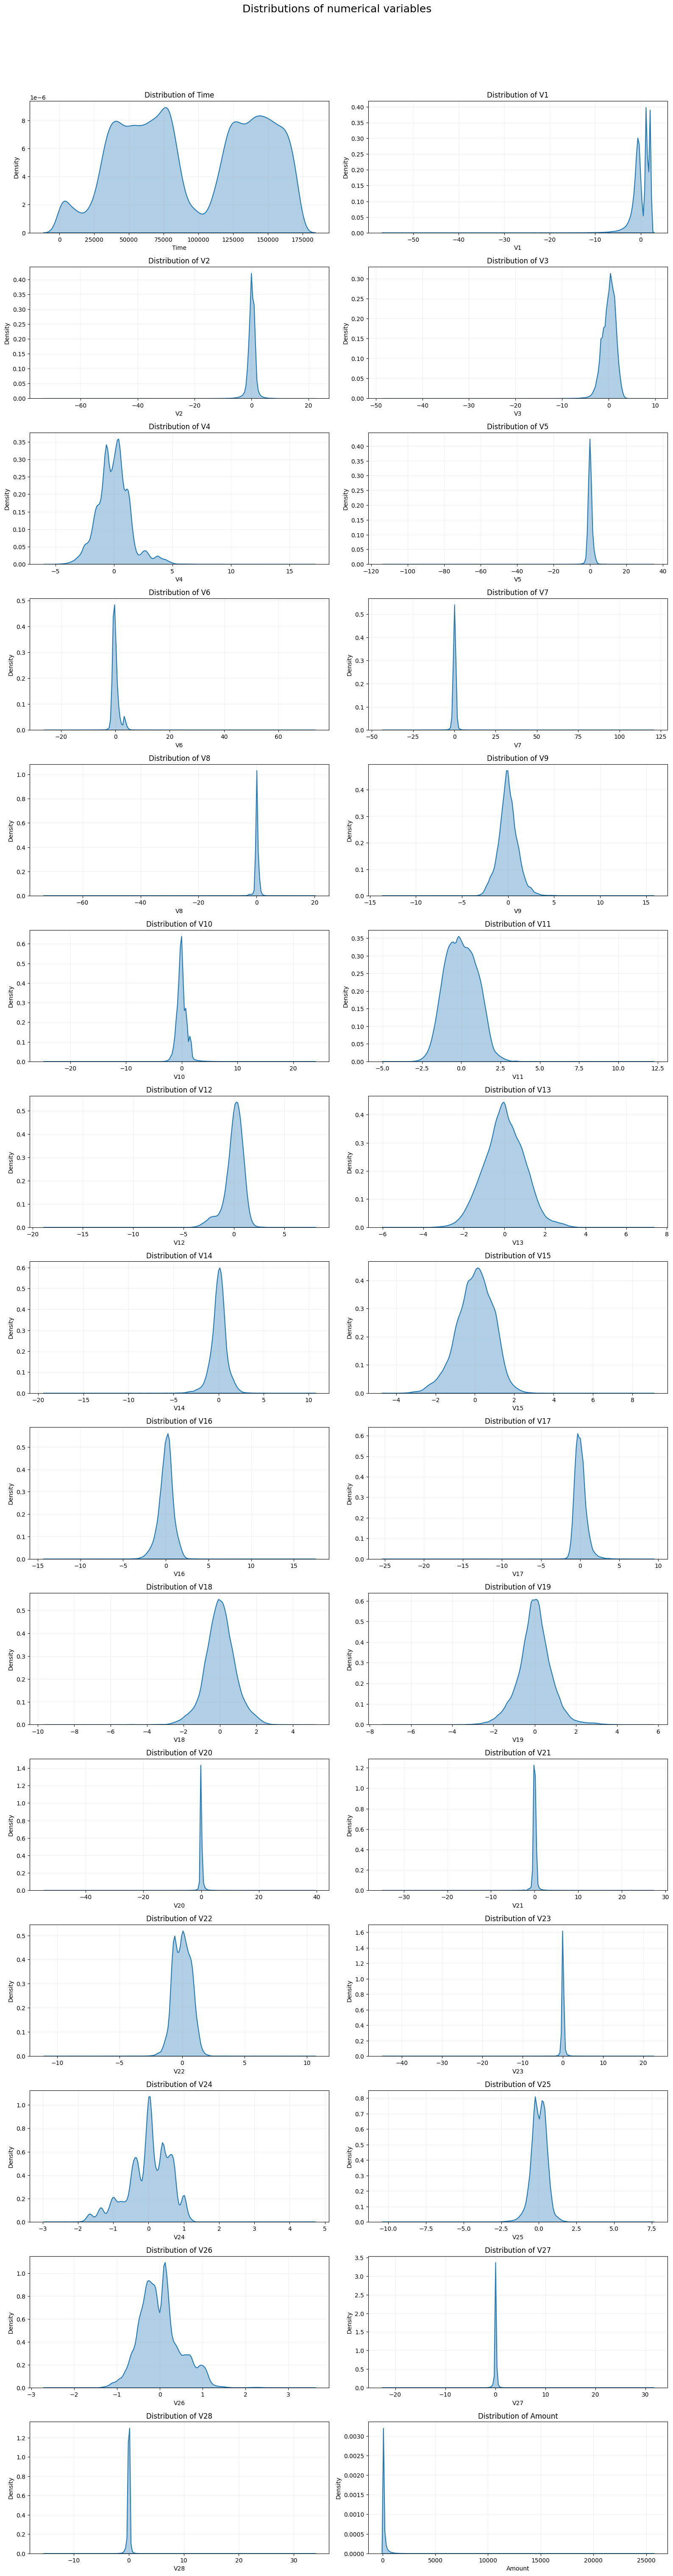

In [11]:
numeric_cols = df.columns.drop('Class')
n = len(numeric_cols)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 1 + 4.0*nrows))
axes = axes.flatten() if n > 1 else [axes]

for idx, col in enumerate(numeric_cols):
    ax = axes[idx]
    s = df[col].dropna()
    sns.kdeplot(s, fill=True, alpha=0.35, linewidth=1.5, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_ylabel("Density")
    ax.grid(True, alpha=0.2)

for j in range(n, nrows*ncols):
    axes[j].set_visible(False)

plt.suptitle("Distributions of numerical variables", fontsize=18, y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

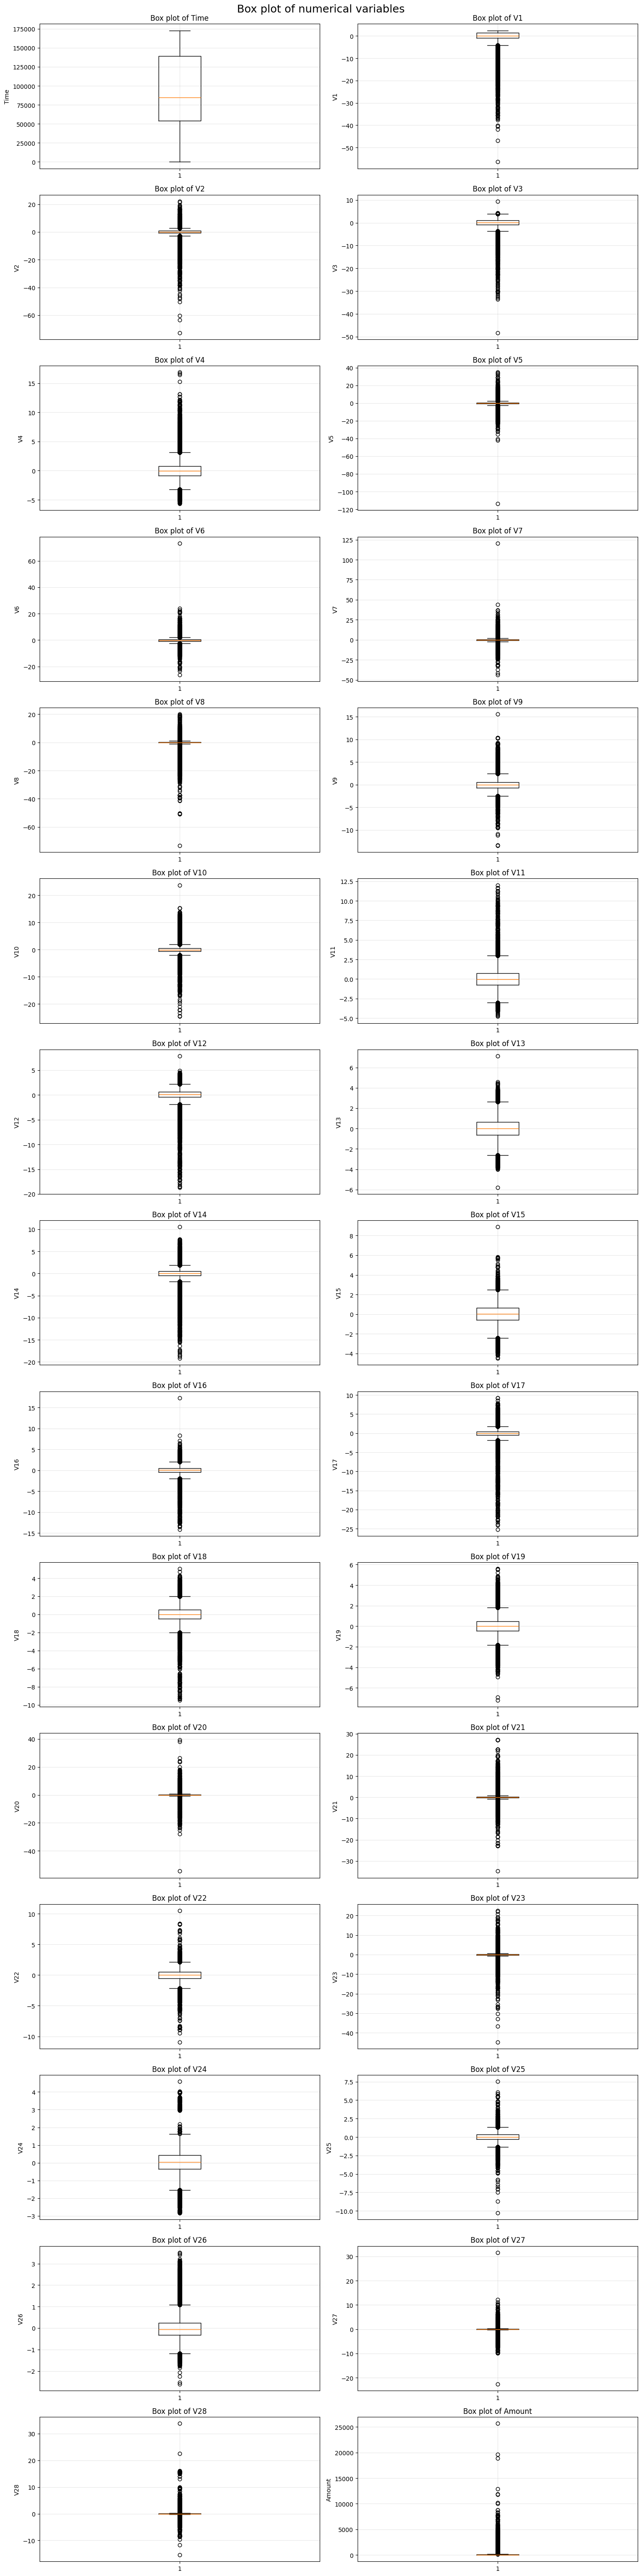

In [12]:
# for outlier detection
n = len(numeric_cols)
ncols = 2
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.ravel()
for idx, col in enumerate(numeric_cols):
    axes[idx].boxplot(df[col], vert=True)
    axes[idx].set_title(f'Box plot of {col}')
    axes[idx].set_ylabel(col, fontsize=10)
    axes[idx].grid(alpha=0.3)
# Ẩn các ô thừa
for idx in range(n, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Box plot of numerical variables", fontsize=18, y=0.995)
plt.tight_layout()
plt.show()

Nearly all numerical variables contain potential outliers.

### 3.4. Correlation Analysis:

Understanding the relationships between numerical features using **Pearson Correlation**.

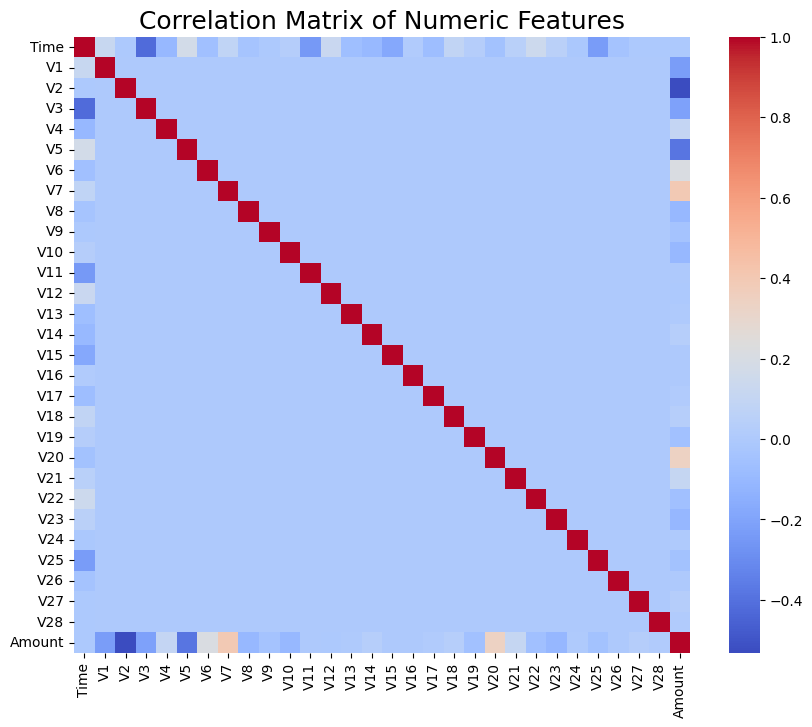

In [13]:
corr = df[numeric_cols].corr(method="pearson")
plt.figure(figsize=(10,8))
sns.heatmap(corr, fmt=".2f", cmap="coolwarm", cbar=True, square=True)
plt.title("Correlation Matrix of Numeric Features", fontsize=18)
plt.show()

### 3.5. Feature-Target Correlations:

**Analyze the relationship between key features and the target variable:**

Top 15 features correlated with Class:
V17    0.326481
V14    0.302544
V12    0.260593
V10    0.216883
V16    0.196539
V3     0.192961
V7     0.187257
V11    0.154876
V4     0.133447
V18    0.111485
V1     0.101347
V9     0.097733
V5     0.094974
V2     0.091289
V6     0.043643
Name: Class, dtype: float64


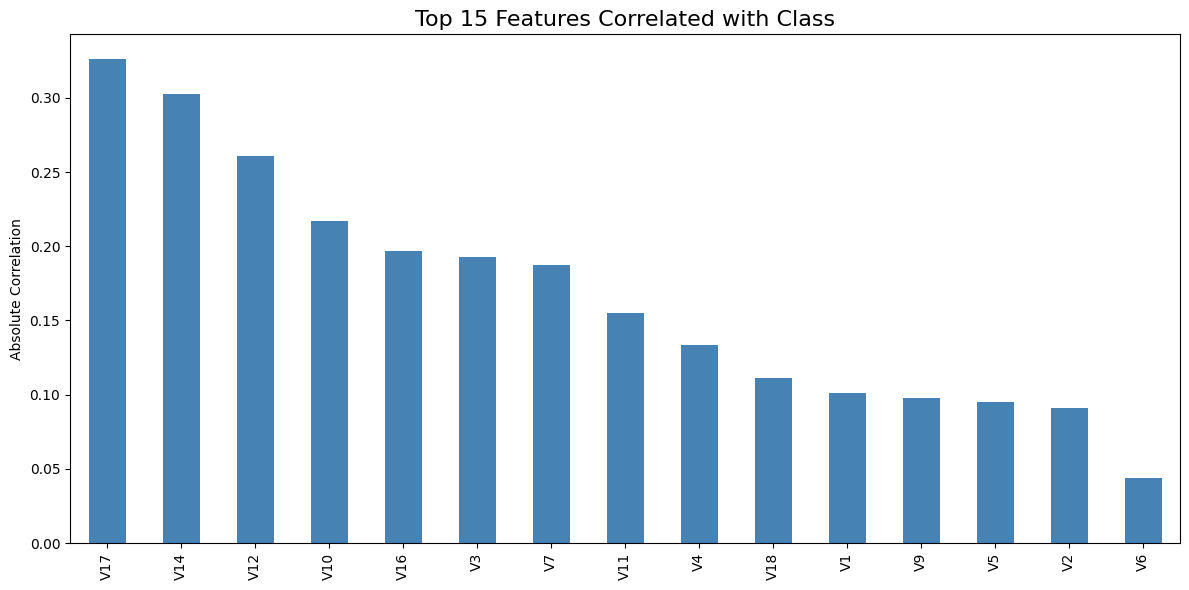

In [14]:
# Top correlations with target variable
corr_with_class = df.corr()['Class'].drop('Class').abs().sort_values(ascending=False)
print("Top 15 features correlated with Class:")
print(corr_with_class.head(15))

# Visualize
plt.figure(figsize=(12, 6))
corr_with_class.head(15).plot(kind='bar', color='steelblue')
plt.title('Top 15 Features Correlated with Class', fontsize=16)
plt.ylabel('Absolute Correlation')
plt.tight_layout()
plt.show()

**Analyze the distribution of features across fraudulent and non-fraudulent transactions:**

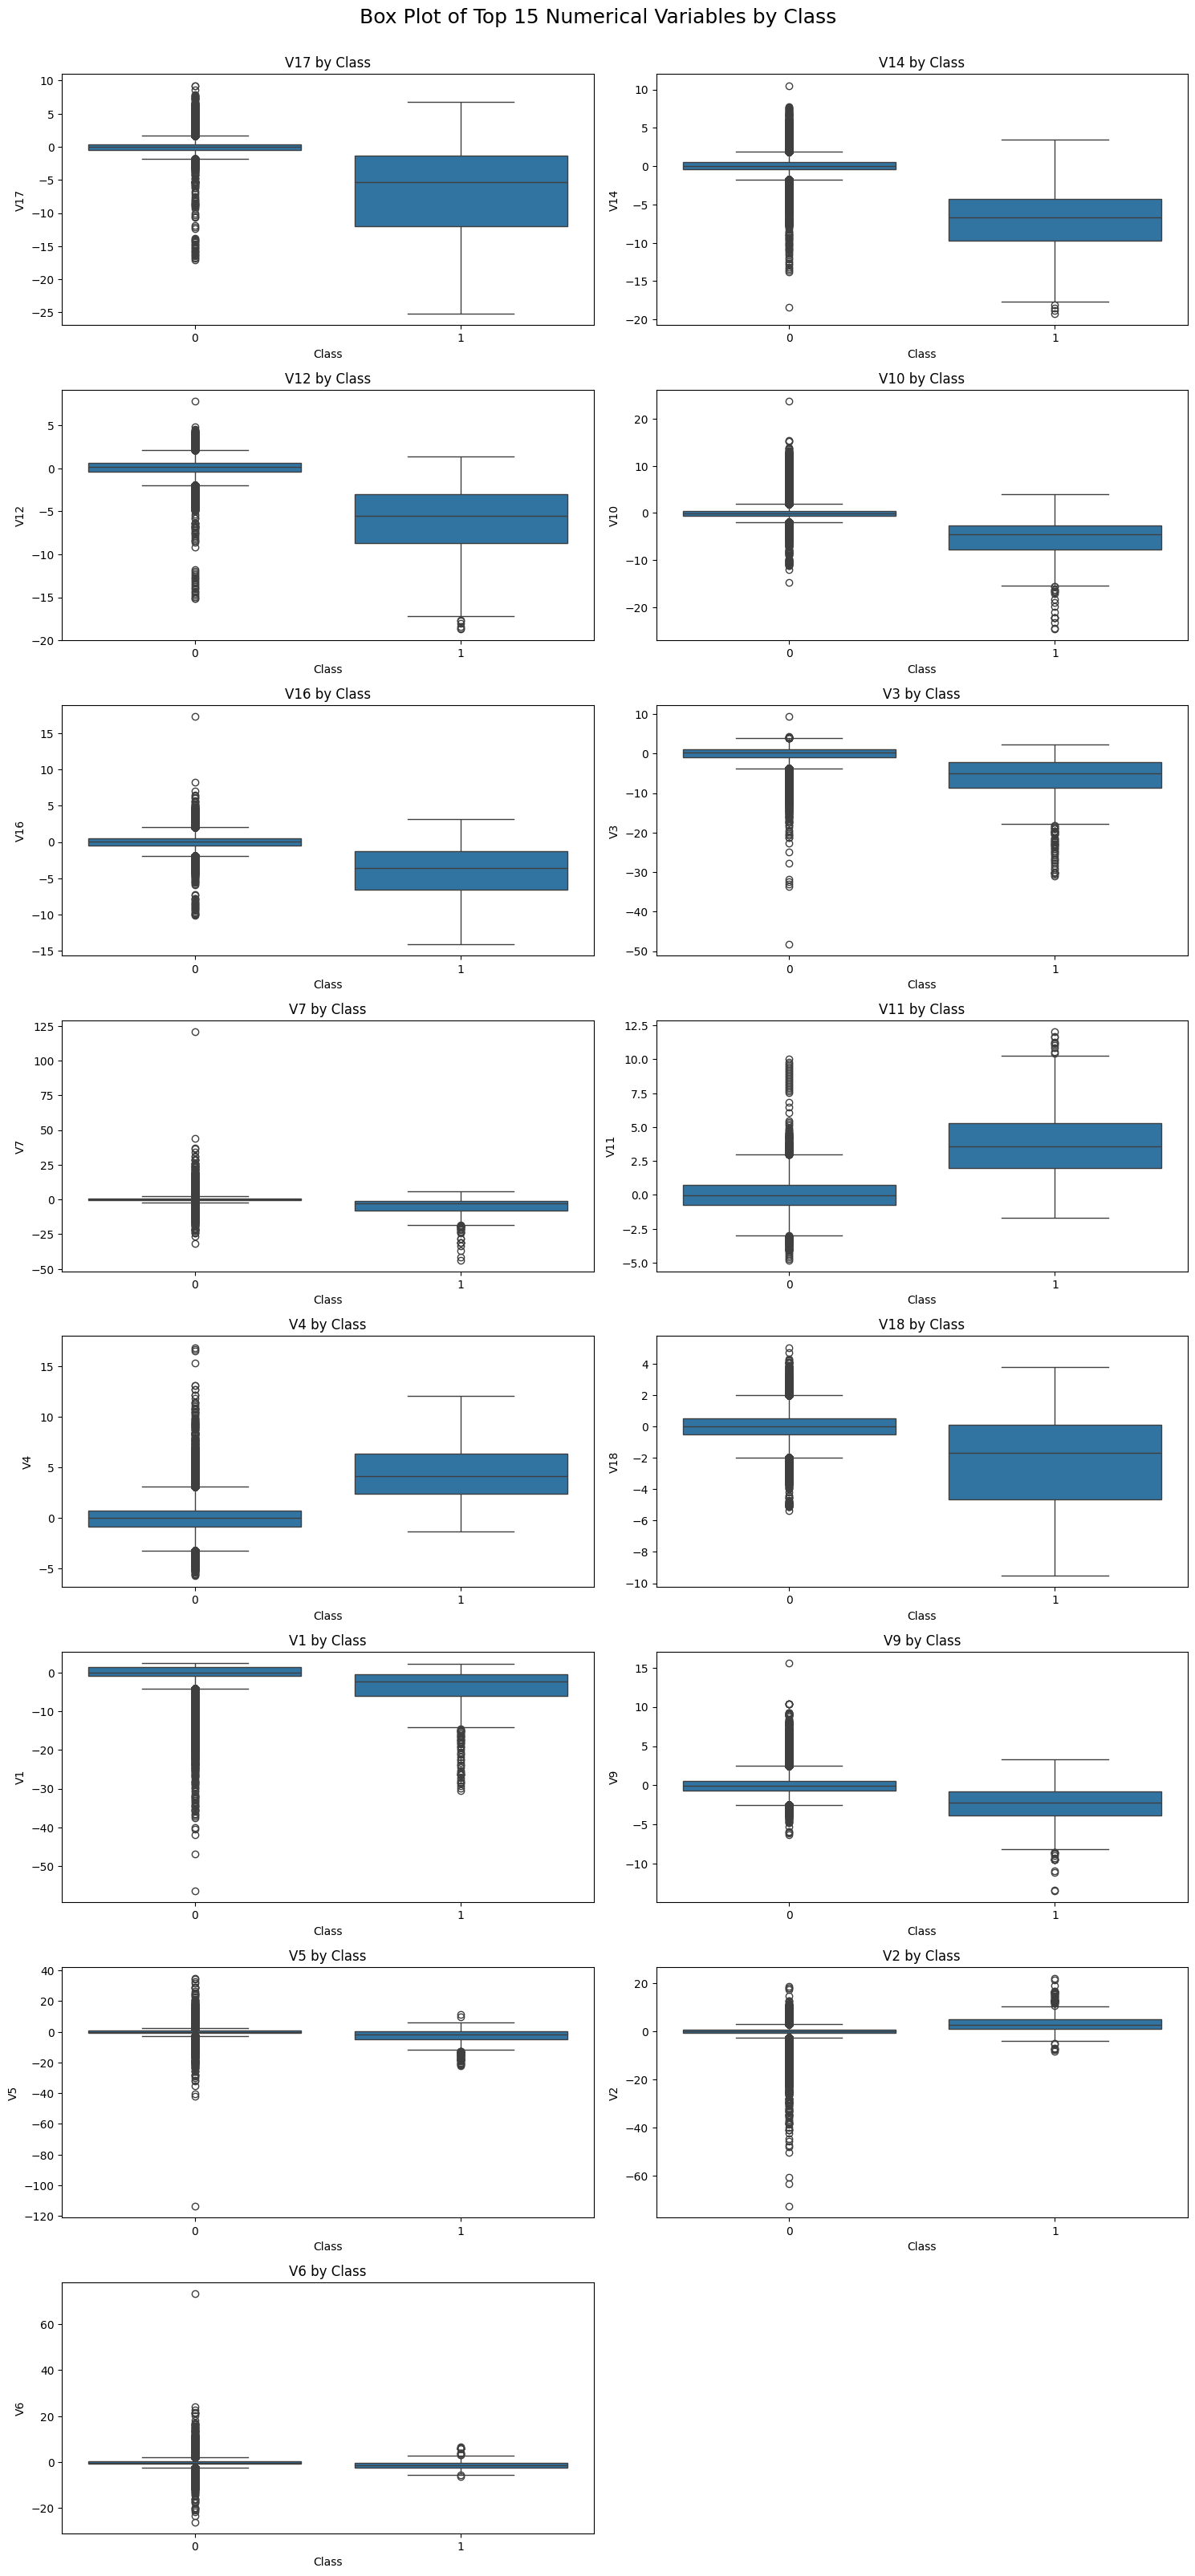

In [15]:
top_features = corr_with_class.head(15).index.tolist()
n = len(top_features)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
axes = axes.ravel()

for idx, col in enumerate(top_features):
    sns.boxplot(x='Class', y=col, data=df, ax=axes[idx])
    axes[idx].set_title(f'{col} by Class')

# Ẩn các ô thừa
for idx in range(n, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle("Box Plot of Top 15 Numerical Variables by Class", fontsize=18, y=1.002)
plt.tight_layout()
plt.show()

**Analyze transaction amount and time by fraud status:**

In [16]:
print("Amount Statistics")
print("\nNon-Fraud Transactions:")
print(df[df['Class'] == 0]['Amount'].describe())
print("\nFraud Transactions:")
print(df[df['Class'] == 1]['Amount'].describe())

Amount Statistics

Non-Fraud Transactions:
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Fraud Transactions:
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


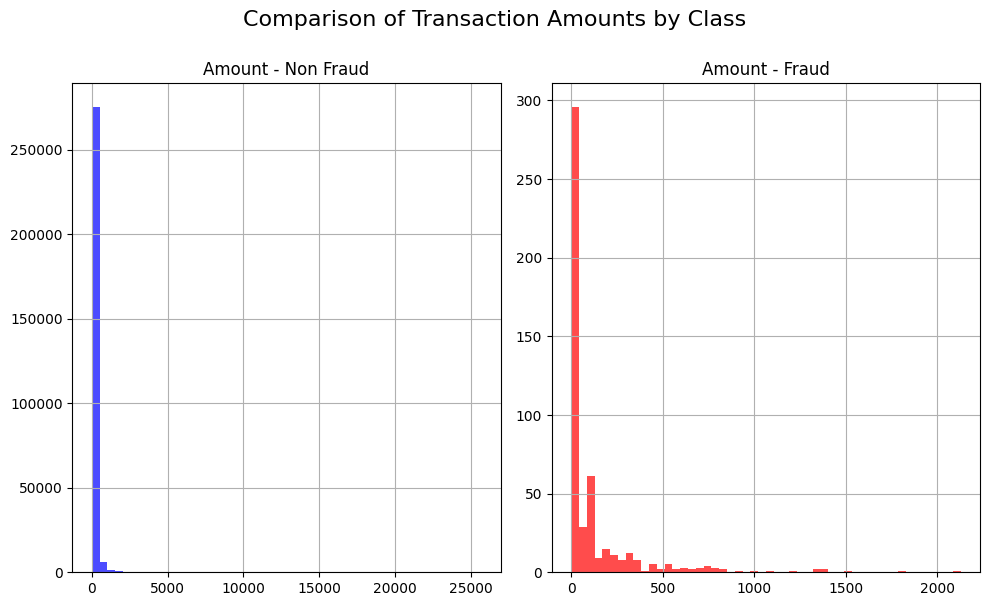

In [17]:
# Amount 
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
df[df['Class'] == 0]['Amount'].hist(bins=50, ax=axes[0], alpha=0.7, color='blue')
axes[0].set_title('Amount - Non Fraud')
df[df['Class'] == 1]['Amount'].hist(bins=50, ax=axes[1], alpha=0.7, color='red')
axes[1].set_title('Amount - Fraud')
plt.suptitle("Comparison of Transaction Amounts by Class", fontsize=16, y=1.002)
plt.tight_layout()
plt.show()


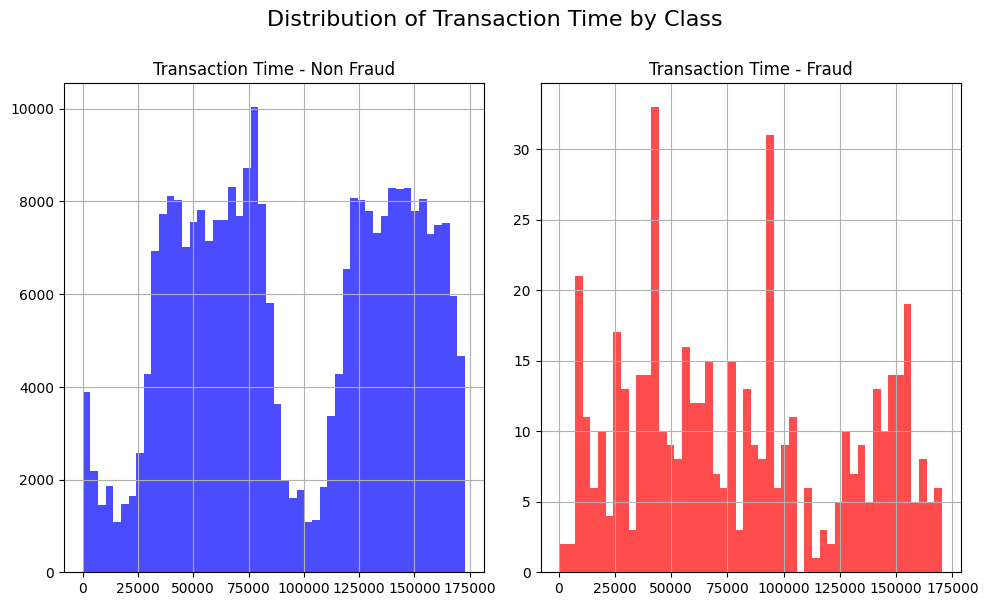

In [18]:
# Distribution of time
fig, axes = plt.subplots(1, 2, figsize=(10, 6))
df[df['Class'] == 0]['Time'].hist(bins=50, ax=axes[0], alpha=0.7, color='blue')
axes[0].set_title('Transaction Time - Non Fraud')
df[df['Class'] == 1]['Time'].hist(bins=50, ax=axes[1], alpha=0.7, color='red')
axes[1].set_title('Transaction Time - Fraud')
plt.suptitle("Distribution of Transaction Time by Class", fontsize=16, y=1.002)
plt.tight_layout()
plt.show()

## 4. Key Insights and Recommendations:

Summary of findings from the exploratory data analysis.
- **Missing values**: No missing values found.
- **Duplicates**: There are 1081 duplicate rows that need to be handled before training the models.
- **Features V1-V28**: After applying PCA, the mean of these features is approximately 0.
- **Class imbalance**: A significant class imbalance was detected, with 99.8% non-fraud and 0.2% fraud transactions.
- **Key correlations**: Top features, which have strong correlation with `Class` variables, including V17, V14, V12,...

Recommendations:
- Use stratified sampling for train/val/test split.
- Apply oversampling techniques (e.g., SMOTE, BorderlineSMOTE,...) to handle the class imbalance in this dataset.
- Feature scaling is recommended for the numerical features.
- Consider ensemble methods (Random Forest, Gradient Boosting,...).

EDA COMPLETE! Ready for modeling.